# Train Test Splits, Cross Validation, and Linear Regression

![Lregressions.png](Assets/linearRegr.png)

# Learning Objectives

- Explicarea diferenței dintre supraadaptarea și subadaptarea unui model
- Descrieți compromisurile bias-varianță
- Găsiți împărțirea optimă a seturilor de date de instruire și de testare, validarea încrucișată și complexitatea modelului în funcție de eroare
- Aplicarea unui model de regresie liniară pentru învățarea supravegheată


## Introduction

Vom lucra cu un set de date bazat pe [prețurile locuințelor în Ames, Iowa] (https://www.kaggle.com/c/house-prices-advanced-regression-techniques). Acesta a fost compilat pentru uz educațional pentru a fi o alternativă modernizată și extinsă la binecunoscutul set de date Boston Housing. Această versiune a setului de date a fost completată cu unele valori lipsă pentru comoditate.

Există un număr extins de caracteristici, astfel încât acestea au fost descrise în tabelul de mai jos.

### Predictor

* SalePrice: Prețul de vânzare al proprietății în dolari. 


### Features

<table>
  <tbody>    
    <tr valign="top">
      <td valign="top">
        <ul>
          <li>MoSold: Month Sold</li>
          <li>YrSold: Year Sold</li><br>
          
          <li>SaleType: Type of sale</li>
          <li>SaleCondition: Condition of sale</li><br>

          <li>MSSubClass: The building class</li>
          <li>MSZoning: The general zoning classification</li><br>

          <li>Neighborhood: Physical locations within Ames city limits</li>
          <li>Street: Type of road access</li>
          <li>Alley: Type of alley access</li><br>

          <li>LotArea: Lot size in square feet</li>
          <li>LotConfig: Lot configuration</li>
          <li>LotFrontage: Linear feet of street connected to property</li>
          <li>LotShape: General shape of property</li><br>

          <li>LandSlope: Slope of property</li>
          <li>LandContour: Flatness of the property</li><br>

          <li>YearBuilt: Original construction date</li>
          <li>YearRemodAdd: Remodel date</li>
          <li>OverallQual: Overall material and finish quality</li>
          <li>OverallCond: Overall condition rating</li><br>

          <li>Utilities: Type of utilities available</li>
          <li>Foundation: Type of foundation</li>
          <li>Functional: Home functionality rating</li><br>

          <li>BldgType: Type of dwelling</li>
          <li>HouseStyle: Style of dwelling</li><br>
          
          <li>1stFlrSF: First Floor square feet</li>
          <li>2ndFlrSF: Second floor square feet</li>
          <li>LowQualFinSF: Low quality finished square feet (all floors)</li>
          <li>GrLivArea: Above grade (ground) living area square feet</li>
          <li>TotRmsAbvGrd: Total rooms above grade (does not include bathrooms)</li><br>

          <li>Condition1: Proximity to main road or railroad</li>
          <li>Condition2: Proximity to main road or railroad (if a second is present)</li><br>
          
          <li>RoofStyle: Type of roof</li>
          <li>RoofMatl: Roof material</li><br>

          <li>ExterQual: Exterior material quality</li>
          <li>ExterCond: Present condition of the material on the exterior</li>
          <li>Exterior1st: Exterior covering on house</li>
          <li>Exterior2nd: Exterior covering on house (if more than one material)</li><br><br>
          
        </ul>
      </td>
      
      <td valign="top">
        <ul>
          <li>MasVnrType: Masonry veneer type</li>
          <li>MasVnrArea: Masonry veneer area in square feet</li><br>
          
          <li>WoodDeckSF: Wood deck area in square feet</li>
          <li>OpenPorchSF: Open porch area in square feet</li>
          <li>EnclosedPorch: Enclosed porch area in square feet</li>
          <li>3SsnPorch: Three season porch area in square feet</li>
          <li>ScreenPorch: Screen porch area in square feet</li><br>

          <li>PoolArea: Pool area in square feet</li>
          <li>PoolQC: Pool quality</li>
          <li>Fence: Fence quality</li>
          <li>PavedDrive: Paved driveway</li><br>

          <li>GarageType: Garage location</li>
          <li>GarageYrBlt: Year garage was built</li>
          <li>GarageFinish: Interior finish of the garage</li>
          <li>GarageCars: Size of garage in car capacity</li>
          <li>GarageArea: Size of garage in square feet</li>
          <li>GarageQual: Garage quality</li>
          <li>GarageCond: Garage condition</li><br>

          <li>Heating: Type of heating</li>
          <li>HeatingQC: Heating quality and condition</li>
          <li>CentralAir: Central air conditioning</li>
          <li>Electrical: Electrical system</li><br>
          
          <li>FullBath: Full bathrooms above grade</li>
          <li>HalfBath: Half baths above grade</li><br>
          
          <li>BedroomAbvGr: Number of bedrooms above basement level</li><br>
          
          <li>KitchenAbvGr: Number of kitchens</li>
          <li>KitchenQual: Kitchen quality</li><br>
          
          <li>Fireplaces: Number of fireplaces</li>
          <li>FireplaceQu: Fireplace quality</li><br>
          
          <li>MiscFeature: Miscellaneous feature not covered in other categories</li>
          <li>MiscVal: Value of miscellaneous feature</li><br>
          
          <li>BsmtQual: Height of the basement</li>
          <li>BsmtCond: General condition of the basement</li>
          <li>BsmtExposure: Walkout or garden level basement walls</li>
          <li>BsmtFinType1: Quality of basement finished area</li>
          <li>BsmtFinSF1: Type 1 finished square feet</li>
          <li>BsmtFinType2: Quality of second finished area (if present)</li>
          <li>BsmtFinSF2: Type 2 finished square feet</li>
          <li>BsmtUnfSF: Unfinished square feet of basement area</li>
          <li>BsmtFullBath: Basement full bathrooms</li>
          <li>BsmtHalfBath: Basement half bathrooms</li>
          <li>TotalBsmtSF: Total square feet of basement area</li>
        </ul>
      </td>
    </tr>
    
  </tbody>
</table>


In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

DATA_DIR = 'data' if os.path.isdir('data') else '.'

def load_ames():
    """Încarcă setul Ames (CSV dacă există, altfel XLSX)."""
    csv  = os.path.join(DATA_DIR, 'Ames_Housing_Sales.csv')
    xlsx = os.path.join(DATA_DIR, 'Ames_Housing_Sales.xlsx')
    return pd.read_csv(csv) if os.path.exists(csv) else pd.read_excel(xlsx)

RANDOM_STATE = 42

## Question 1

* Importați datele utilizând Pandas și examinați forma. Există 79 de coloane de caracteristici plus predictorul, prețul de vânzare (`SalePrice`). 
* Există trei tipuri diferite: numere întregi (`int64`), numere float (`float64`) și șiruri de caractere (`object`, categoricals). Examinați câte există din fiecare tip de date. 

In [2]:
data = load_ames()
print("Forma setului de date:", data.shape, "(rânduri, coloane)")
print("Coloane de caracteristici:", data.shape[1] - 1, "+ predictorul SalePrice")

# Numărul de coloane pe tip de date (șirurile de caractere = 'object')
tipuri = data.dtypes.astype(str).replace({'str': 'object', 'string': 'object'})
print("\nNumăr de coloane pe tip de date:")
print(tipuri.value_counts())

# ---- Verificare calitate date: valori numerice imposibile ----
# LotFrontage (front stradal, în ft) are valori ~1e16 în 251 de rânduri, imposibile (maximul real în Ames este ~313 ft).
# Sunt „lipsuri” completate cu zgomot; le tratăm ca valori lipsă, altfel distrug regresia liniară.
print("LotFrontage: valori > 1000 :", (data['LotFrontage'] > 1000).sum(), "| maxim:", f"{data['LotFrontage'].max():.3e}")
data.loc[data['LotFrontage'] > 1000, 'LotFrontage'] = np.nan
print("LotFrontage după curățare: maxim =", data['LotFrontage'].max())

# Valori lipsă
lipsa = data.isnull().sum()
print("\nColoane cu valori lipsă:", (lipsa > 0).sum())
print(lipsa[lipsa > 0].sort_values(ascending=False).head(10))

Forma setului de date: (1379, 80) (rânduri, coloane)
Coloane de caracteristici: 79 + predictorul SalePrice

Număr de coloane pe tip de date:
object     43
float64    21
int64      16
Name: count, dtype: int64
LotFrontage: valori > 1000 : 251 | maxim: 6.079e+16
LotFrontage după curățare: maxim = 313.0

Coloane cu valori lipsă: 12
PoolQC          1372
MiscFeature     1328
Alley           1297
Fence           1114
MasVnrType       797
FireplaceQu      618
BsmtFinType2     427
BsmtCond         426
BsmtFinType1     426
BsmtExposure     426
dtype: int64


Setul are **1379 de rânduri și 80 de coloane** (79 de caracteristici + `SalePrice`). Tipurile de date: **43 `object`** (șiruri categoriale), **21 `float64`** și **16 `int64`**.

*Notă despre calitatea datelor:* coloana `LotFrontage` are 251 de valori imposibile (de ordinul 10¹⁶, în timp ce maximul real în Ames este ~313 ft). Par „lipsuri” completate cu zgomot, așa că le-am tratat drept valori lipsă (apoi imputate cu mediana). Fără această curățare, regresia liniară nu explică aproape nimic (RMSE ≈ 77 000 $, aproape de abaterea standard a prețului).

## Question 2

După cum s-a discutat în prelegere, o provocare semnificativă, în special atunci când este vorba de date care au mai multe coloane, este să se asigure că fiecare coloană este codificată corect. 

Acest lucru este valabil în special în cazul coloanelor de date care sunt categorice ordonate (ordonate) vs. categorice neordonate. Categoriile neordonate ar trebui să fie codificate o singură dată, însă acest lucru poate crește semnificativ numărul de caracteristici și creează caracteristici care sunt foarte corelate între ele.

Determinați câte caracteristici totale ar fi prezente, în raport cu ceea ce există în prezent, dacă toate caracteristicile șirurilor (obiectelor) sunt codificate o singură dată. Reamintim că numărul total de coloane cu codificare one-hot este `n-1`, unde `n` este numărul de categorii.

In [3]:
# În acest set, lipsa unei valori înseamnă adesea „fără acea caracteristică” (de ex. fără pivniță, fără alee).
# Tratăm lipsa din coloanele categoriale ca o categorie proprie: 'None'.
cat_cols = data.select_dtypes(include=['object', 'string']).columns.tolist()
num_cols = [c for c in data.columns if c not in cat_cols and c != 'SalePrice']

n_categorii = data[cat_cols].fillna('None').nunique().sort_values(ascending=False)
print("Coloane categoriale (object):", len(cat_cols))
print("Coloane numerice (fără SalePrice):", len(num_cols))
print("\nNumăr de categorii pe coloană (top 10):")
print(n_categorii.head(10))

coloane_onehot = int((n_categorii - 1).sum())          # n-1 coloane pentru fiecare variabilă categorială
total_actual = len(num_cols) + len(cat_cols)
total_onehot = len(num_cols) + coloane_onehot
print(f"\nCaracteristici în prezent       : {total_actual}")
print(f"Caracteristici după one-hot     : {total_onehot}  ( = {len(num_cols)} numerice + {coloane_onehot} codificate)")
print(f"Creștere                        : +{total_onehot - total_actual} coloane (x{total_onehot / total_actual:.1f})")

Coloane categoriale (object): 43
Coloane numerice (fără SalePrice): 36

Număr de categorii pe coloană (top 10):
Neighborhood    25
Exterior2nd     16
Exterior1st     14
SaleType         9
Condition1       9
RoofMatl         8
HouseStyle       8
Condition2       8
Functional       7
BsmtFinType2     7
dtype: int64

Caracteristici în prezent       : 79
Caracteristici după one-hot     : 251  ( = 36 numerice + 215 codificate)
Creștere                        : +172 coloane (x3.2)


 Avem 43 de coloane categoriale și 36 numerice (fără `SalePrice`), deci **79 de caracteristici** în prezent. Prin codificare one-hot cu `n-1` coloane pe variabilă, cele 43 de coloane devin **215 coloane**, iar totalul crește la **251 de caracteristici** (36 + 215), adică **+172 de coloane (de ~3,2 ori mai multe)**. (Lipsa valorii a fost tratată ca o categorie separată, `None`.) Variabila cu cele mai multe categorii este `Neighborhood` (25).

## Question 3

Să creăm un nou set de date în care toate caracteristicile categorice de mai sus vor fi codificate o singură dată. Putem ajusta aceste date și să vedem cum afectează rezultatele.

* Am folosit metoda `.copy()` a cadrului de date pentru a crea o copie complet separată a cadrului de date pentru codificarea one-hot
* Pe acest nou cadru de date, codificați o singură dată fiecare dintre coloanele corespunzătoare și adăugați-o înapoi la cadrul de date. Asigurați-vă că renunțați la coloana originală.
* Pentru datele care nu sunt codificate o singură dată, renunțați la coloanele care sunt șiruri categoriale.

Pentru primul pas, codificarea numerică a categoriilor de șiruri, se poate utiliza `LabelEncoder` sau `DictVectorizer` din Scikit-learn. Cu toate acestea, primul este probabil mai ușor, deoarece nu necesită specificarea unei valori numerice pentru fiecare categorie, iar noi vom codifica oricum toate valorile numerice printr-o singură dată. (Vă puteți gândi la un moment în care `DictVectorizer` ar putea fi preferat?)

In [4]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

# Valorile lipsă: categorial -> 'None'; numeric -> mediana coloanei
data_clean = data.copy()
data_clean[cat_cols] = data_clean[cat_cols].fillna('None')
for c in data_clean.columns[data_clean.isnull().any()]:
    data_clean[c] = data_clean[c].fillna(data_clean[c].median())

# ---- Setul 1: FĂRĂ one-hot -> eliminăm coloanele șir ----
data_simple = data_clean.drop(columns=cat_cols)

# ---- Setul 2: CU one-hot (copie separată) ----
data_ohe = data_clean.copy()
for col in cat_cols:
    le = LabelEncoder()
    lab = le.fit_transform(data_ohe[[col]].squeeze())                       # pasul 1: șir -> număr
    oh = OneHotEncoder(drop='first', sparse_output=False)                  # pasul 2: n-1 coloane one-hot
    arr = oh.fit_transform(lab.reshape(-1, 1))
    names = [f"{col}_{le.classes_[i]}" for i in oh.categories_[0][1:]]
    data_ohe = pd.concat([data_ohe.drop(columns=col), pd.DataFrame(arr, columns=names, index=data_ohe.index)], axis=1)

print("Set fără one-hot:", data_simple.shape)
print("Set cu one-hot  :", data_ohe.shape, "(așteptat:", total_onehot + 1, "coloane, incluzând SalePrice)")
print("Valori lipsă rămase:", data_simple.isnull().sum().sum(), "/", data_ohe.isnull().sum().sum())

Set fără one-hot: (1379, 37)
Set cu one-hot  : (1379, 252) (așteptat: 252 coloane, incluzând SalePrice)
Valori lipsă rămase: 0 / 0


 Au rezultat două seturi: **fără one-hot** (37 de coloane: 36 de caracteristici numerice + `SalePrice`) și **cu one-hot** (252 de coloane), fără valori lipsă.

*Când ar fi preferat `DictVectorizer`?* Când datele sunt deja sub formă de dicționare/înregistrări (de ex. JSON, liste de dicționare) cu caracteristici amestecate numerice și categoriale: el codifică direct, într-un singur pas, fără trecerea prin `LabelEncoder`, și poate returna o **matrice rară**, avantajoasă pentru variabile cu foarte multe categorii. Păstrează și numele caracteristicilor, iar pentru caracteristici lipsă dintr-un dicționar pur și simplu nu generează coloană.

## Question 4

* Creați împărțiri de instruire și de testare ale ambelor seturi de date. Pentru a vă asigura că datele sunt împărțite în același mod, utilizați același `random_state` în fiecare dintre cele două împărțiri.
* Pentru fiecare set de date, ajustați un model de regresie liniară de bază pe datele de antrenament. 
* Calculați eroarea pătratică medie pe seturile de antrenament și de testare pentru modelele respective. Care model produce o eroare mai mică pe datele de testare și de ce?

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

def split(df):
    X, y = df.drop(columns='SalePrice'), df['SalePrice']
    return train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE)   # același random_state

Xs_tr, Xs_te, ys_tr, ys_te = split(data_simple)
Xo_tr, Xo_te, yo_tr, yo_te = split(data_ohe)
assert (ys_tr.index == yo_tr.index).all()          # aceleași rânduri în ambele împărțiri

rows = {}
for name, (Xtr, Xte, ytr, yte) in {'fără one-hot': (Xs_tr, Xs_te, ys_tr, ys_te),
                                    'cu one-hot':  (Xo_tr, Xo_te, yo_tr, yo_te)}.items():
    lr = LinearRegression().fit(Xtr, ytr)
    rows[name] = {'nr. caracteristici': Xtr.shape[1],
                  'MSE train': mean_squared_error(ytr, lr.predict(Xtr)),
                  'MSE test':  mean_squared_error(yte, lr.predict(Xte)),
                  'RMSE train': mean_squared_error(ytr, lr.predict(Xtr)) ** .5,
                  'RMSE test':  mean_squared_error(yte, lr.predict(Xte)) ** .5}
res4 = pd.DataFrame(rows).T
pd.options.display.float_format = '{:,.2f}'.format
display(res4)

,nr. caracteristici,MSE train,MSE test,RMSE train,RMSE test
fără one-hot,36.00,"1,132,588,964.30","1,384,594,315.79","33,653.96","37,210.14"
cu one-hot,251.00,"318,290,507.50","4,969,953,507.96","17,840.70","70,497.90"


 Modelul **fără one-hot** are eroarea mai mică pe datele de test: RMSE ≈ **37 210 $** față de ≈ **70 498 $** pentru modelul cu one-hot (MSE ≈ 1,38·10⁹ față de 4,97·10⁹), modelul cu one-hot are 251 de caracteristici pentru doar 965 de rânduri de antrenare. Are bias mic, dar **varianță mare**: eroarea de antrenare este foarte mică (RMSE ≈ 17 841 $, față de 33 654 $ fără one-hot), însă eroarea de test aproape se dublează, ceea ce este semnul clasic de **supraadaptare (overfitting)**. Multe dintre coloanele one-hot descriu categorii rare (de ex. anumite cartiere, materiale de acoperiș sau exterior) care apar la doar câteva case, iar modelul le memorează în loc să învețe tipare generale; în plus, coloanele one-hot sunt puternic corelate între ele (multicoliniaritate). Modelul simplu are mai puține grade de libertate, deci generalizează mai bine.

Rețineți că valorile erorilor privind datele codificate printr-o singură lovitură sunt foarte diferite pentru datele de formare și cele de testare. În special, erorile privind datele de testare sunt mult mai mari. Pe baza lecției, acest lucru se datorează faptului că modelul codificat o singură dată se potrivește prea bine datelor. Vom învăța cum să rezolvăm astfel de probleme în lecția următoare.

## Question 5

Pentru fiecare dintre seturile de date (codificate la cald și necodificate):

* Scalați toate valorile codificate non-hot utilizând una dintre următoarele metode: `StandardScaler`, `MinMaxScaler`, `MaxAbsScaler`.
* Comparați eroarea calculată pe seturile de testare

Asigurați-vă că calculați oblicitatea (pentru a decide dacă trebuie efectuată o transformare) și ajustați scalerul pe *NUMai* datele de formare, dar apoi aplicați-l identic atât pe datele de formare, cât și pe cele de testare.

In [6]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, MaxAbsScaler

# --- Oblicitatea (skewness) calculată NUMAI pe datele de antrenare, pe coloanele numerice originale ---
skew = Xs_tr.skew().sort_values(ascending=False)
skewed = skew[skew.abs() > 0.75].index.tolist()
print(f"Caracteristici cu |skew| > 0.75: {len(skewed)} din {Xs_tr.shape[1]}")
print(skew.head(8).round(2))

def log_transform(X, cols):
    X = X.copy()
    X[cols] = np.log1p(X[cols].clip(lower=0))
    return X

def evaluate(Xtr, Xte, ytr, yte):
    m = LinearRegression().fit(Xtr, ytr)
    return mean_squared_error(yte, m.predict(Xte))

orig_cols = Xs_tr.columns                       # coloanele numerice originale (non-one-hot)
results = []
for dname, (Xtr, Xte, ytr, yte) in {'fără one-hot': (Xs_tr, Xs_te, ys_tr, ys_te),
                                     'cu one-hot':  (Xo_tr, Xo_te, yo_tr, yo_te)}.items():
    results.append({'set': dname, 'transformare': 'fără scalare', 'MSE test': evaluate(Xtr, Xte, ytr, yte)})

    Xtr_l, Xte_l = log_transform(Xtr, skewed), log_transform(Xte, skewed)
    results.append({'set': dname, 'transformare': 'log pe skew', 'MSE test': evaluate(Xtr_l, Xte_l, ytr, yte)})

    for sname, S in {'StandardScaler': StandardScaler, 'MinMaxScaler': MinMaxScaler, 'MaxAbsScaler': MaxAbsScaler}.items():
        sc = S().fit(Xtr_l[orig_cols])                           # fit NUMAI pe train
        A, B = Xtr_l.copy(), Xte_l.copy()
        A[orig_cols] = sc.transform(Xtr_l[orig_cols])           # scalăm doar coloanele non-one-hot
        B[orig_cols] = sc.transform(Xte_l[orig_cols])
        results.append({'set': dname, 'transformare': f'log + {sname}', 'MSE test': evaluate(A, B, ytr, yte)})

tab5 = pd.DataFrame(results).pivot(index='transformare', columns='set', values='MSE test')
display(tab5)

Caracteristici cu |skew| > 0.75: 23 din 36
MiscVal        26.92
PoolArea       15.78
LotArea        11.50
LowQualFinSF   11.21
3SsnPorch      10.15
KitchenAbvGr    5.50
ScreenPorch     4.60
BsmtFinSF2      4.47
dtype: float64


set,cu one-hot,fără one-hot
transformare,,
fără scalare,"4,969,953,507.96","1,384,594,315.79"
log + MaxAbsScaler,"6,168,396,227.22","1,331,436,012.02"
log + MinMaxScaler,"6,168,396,227.22","1,331,436,012.02"
log + StandardScaler,"6,168,396,227.22","1,331,436,012.02"
log pe skew,"6,168,396,227.22","1,331,436,012.02"


Pe datele de antrenare, 23 din cele 36 de caracteristici numerice au |skew| > 0,75 (cele mai asimetrice: `MiscVal` ≈ 26,9, `PoolArea` ≈ 15,8, `LotArea` ≈ 11,5), deci am aplicat o transformare logaritmică `log(1+x)` (decisă numai pe train). Apoi am scalat doar coloanele non-one-hot, cu scalerul ajustat pe train.

| MSE test | fără one-hot | cu one-hot |
|---|---|---|
| fără transformări | 1,385·10⁹ | 4,970·10⁹ |
| log + (Standard / MinMax / MaxAbs) | **1,331·10⁹** | 6,168·10⁹ |

Observăm că **Cele trei scalere dau exact aceeași eroare.** Regresia liniară obișnuită (OLS, cu termen liber) este invariantă la transformări afine ale caracteristicilor: coeficienții se rescalează, iar predicțiile rămân identice. Scalarea devine esențială doar pentru metode sensibile la scală (regularizare, KNN, gradient descent; vezi laboratorul următor).
- Transformarea logaritmică **ajută puțin** modelul simplu (MSE test −3,9%), dar **nu ajută** modelul cu one-hot (eroarea crește), deoarece acesta este dominat de supraadaptare: problema este varianța, nu forma distribuțiilor.
- În continuare, modelul fără one-hot rămâne mai bun pe testare (RMSE ≈ 36,5 mii $ față de ≈ 78,5 mii $).

## Question 6

Reprezentați grafic previziunile față de realitate pentru unul dintre modele.

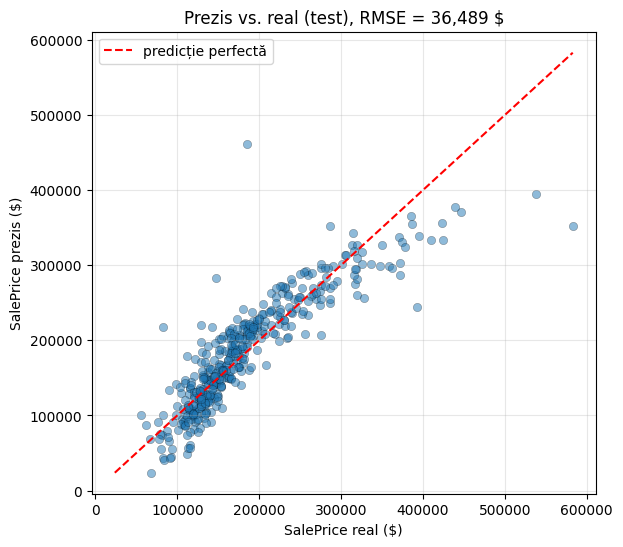

In [7]:
from sklearn.linear_model import LinearRegression

# Modelul ales: regresie liniară pe setul fără one-hot, cu transformare log + StandardScaler
Xtr_l, Xte_l = log_transform(Xs_tr, skewed), log_transform(Xs_te, skewed)
sc = StandardScaler().fit(Xtr_l)
m = LinearRegression().fit(sc.transform(Xtr_l), ys_tr)
pred = m.predict(sc.transform(Xte_l))

plt.figure(figsize=(6.5, 6))
plt.scatter(ys_te, pred, alpha=0.5, edgecolor='k', linewidth=0.3)
lim = [min(ys_te.min(), pred.min()), max(ys_te.max(), pred.max())]
plt.plot(lim, lim, 'r--', label='predicție perfectă')
plt.xlabel('SalePrice real ($)'); plt.ylabel('SalePrice prezis ($)')
plt.title(f'Prezis vs. real (test), RMSE = {mean_squared_error(ys_te, pred) ** .5:,.0f} $')
plt.legend(); plt.grid(alpha=.3); plt.show()

Graficul compară prețul prezis cu cel real pe setul de test pentru regresia liniară pe setul fără one-hot (log + `StandardScaler`, RMSE ≈ 36 500 $). Punctele sunt grupate în jurul diagonalei roșii (predicție perfectă), deci modelul surprinde tendința generală; dispersia crește la prețuri mari (case scumpe sunt subestimate) și apar și câteva predicții greșite pentru case atipice.